# Stroke Prediction: Predictive Modeling Mini Project

**Subject:** Predictive Analytics  |  **Task:** Binary classification  |  **Dataset:** Kaggle Stroke Prediction Dataset (`healthcare-dataset-stroke-data.csv`)

## 1. Problem statement
Stroke is a leading cause of death and long-term disability. If a screening model can flag high-risk patients from routine data (age, blood pressure history, glucose, BMI, lifestyle), clinicians can prioritise them for preventive care.

**Goal:** predict whether a patient has had a stroke (`stroke` = 1) from demographic, medical and lifestyle features.

**Key challenge:** only about 5% of patients are stroke cases, so the data is heavily imbalanced. Plain accuracy is misleading here (predicting "no stroke" for everyone already gives about 95%). The project therefore focuses on recall, precision, F1, ROC-AUC and PR-AUC, and on handling imbalance without data leakage.

## 2. Approach
1. EDA and data cleaning
2. Stratified train/test split (before any resampling or imputation)
3. Preprocessing pipeline (imputation, scaling, one-hot encoding)
4. Baseline plus 3 models, each with class weights and with SMOTE
5. Stratified 5-fold cross-validation
6. Hyperparameter tuning with RandomizedSearchCV
7. Decision-threshold tuning (chosen on training data only)
8. Final test evaluation and interpretation (permutation importance, SHAP)

In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost shap

Note: you may need to restart the kernel to use updated packages.


c:\Users\OJASWITA\.venv313\Scripts\python.exe: No module named pip


In [3]:
import sys
print(sys.executable)


c:\Users\OJASWITA\.venv313\Scripts\python.exe


In [4]:
import pandas as pd
print("Pandas working!")

Pandas working!


In [5]:
import numpy as np
print("NumPy working!")

NumPy working!


In [6]:
import sys
print(sys.executable)

c:\Users\OJASWITA\.venv313\Scripts\python.exe


In [7]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed, using sklearn GradientBoostingClassifier instead.")

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

In [8]:
import pandas as pd
print("Pandas OK")

Pandas OK


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
import xgboost
import shap

print("ALL LIBRARIES WORKING!")

ALL LIBRARIES WORKING!


## 3. Load the data
Download the CSV from Kaggle ("Stroke Prediction Dataset" by fedesoriano) and place it next to this notebook. On Colab, the cell below will ask you to upload it.

In [10]:
DATA_PATH = "healthcare-dataset-stroke-data.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Put '{DATA_PATH}' in the same folder as this notebook.")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [11]:
df.info()
print()
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nGender counts:\n", df["gender"].value_counts())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB

Missing values:
 bmi    201
dtype: int64

Duplicate rows: 0

Gender counts:
 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


## 4. Data cleaning
- `id` is just an identifier, so it is dropped (it carries no signal and would only add noise).
- `gender` has a single "Other" row. One row cannot be learned from or split across train and test, so it is removed.
- `bmi` has missing values. I **do not impute here**: imputing before the split would leak test-set information into training. The imputer is placed inside the pipeline and fitted on training data only.
- "Unknown" in `smoking_status` is kept as its own category, because the missingness may itself be informative (for example, it is common for children).

In [12]:
df = df.drop(columns=["id"])
df = df[df["gender"] != "Other"].reset_index(drop=True)
df["bmi"] = pd.to_numeric(df["bmi"], errors="coerce")
print("Shape after cleaning:", df.shape)
print("Stroke rate: {:.2%}".format(df["stroke"].mean()))

Shape after cleaning: (5109, 11)
Stroke rate: 4.87%


## 5. Exploratory data analysis

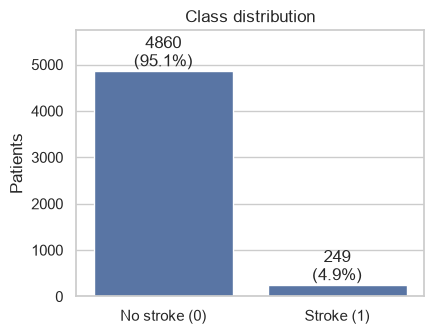

In [13]:
# 5.1 Class imbalance
counts = df["stroke"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.barplot(x=["No stroke (0)", "Stroke (1)"], y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v}\n({v/counts.sum():.1%})", ha="center", va="bottom")
ax.set_title("Class distribution"); ax.set_ylabel("Patients")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.show()

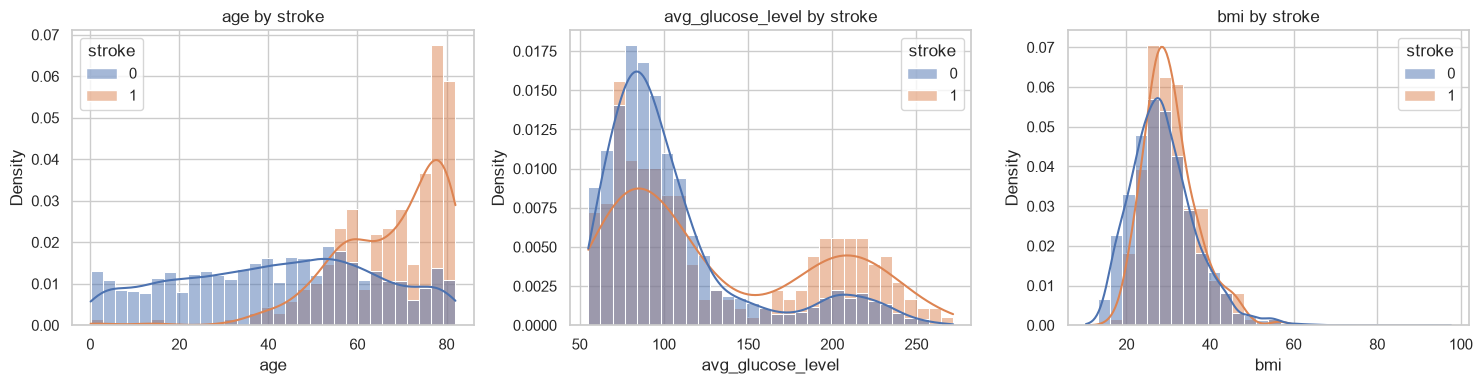

In [14]:
# 5.2 Numeric features vs stroke
num_cols = ["age", "avg_glucose_level", "bmi"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="stroke", stat="density", common_norm=False,
                 kde=True, bins=30, ax=ax)
    ax.set_title(f"{col} by stroke")
plt.tight_layout(); plt.show()

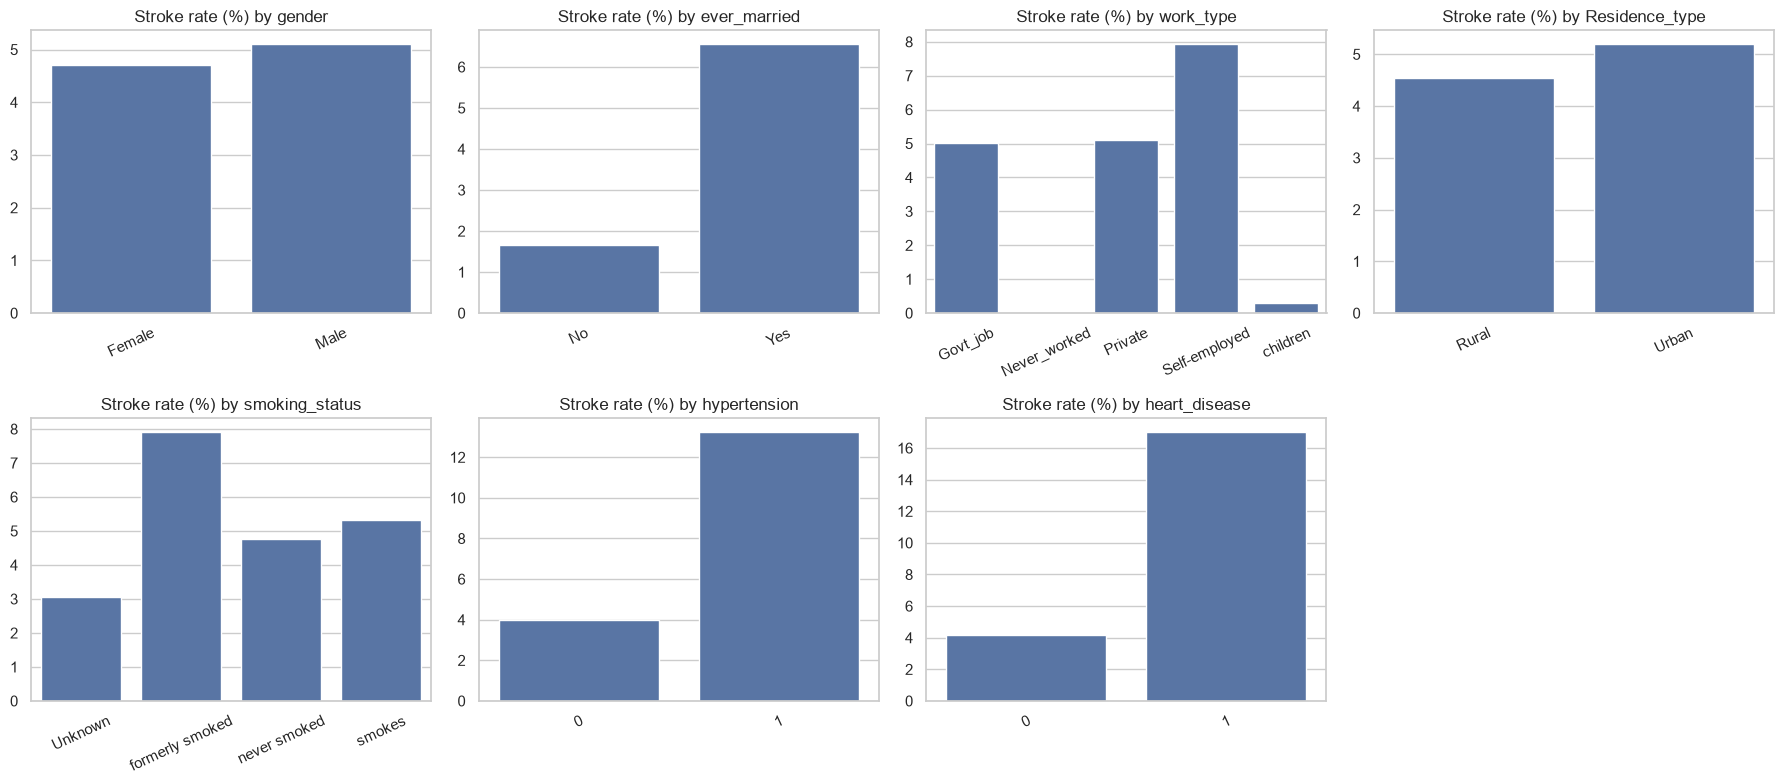

In [15]:
# 5.3 Stroke rate within each category
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
bin_cols = ["hypertension", "heart_disease"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_cols + bin_cols):
    rate = df.groupby(col)["stroke"].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title(f"Stroke rate (%) by {col}")
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

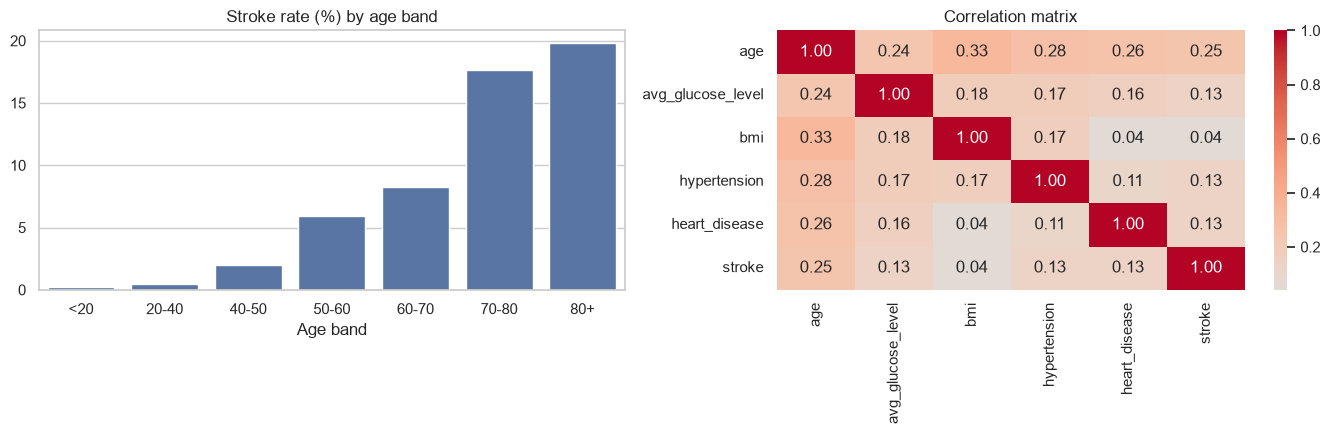

In [16]:
# 5.4 Stroke rate by age band, and correlation heatmap
df["age_band"] = pd.cut(df["age"], bins=[0, 20, 40, 50, 60, 70, 80, 100],
                        labels=["<20", "20-40", "40-50", "50-60", "60-70", "70-80", "80+"])
rate = df.groupby("age_band", observed=True)["stroke"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[0])
axes[0].set_title("Stroke rate (%) by age band"); axes[0].set_xlabel("Age band")

corr = df[["age", "avg_glucose_level", "bmi", "hypertension", "heart_disease", "stroke"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

df = df.drop(columns=["age_band"])

**EDA takeaways (verify against your plots):**
- The data is highly imbalanced (about 5% positives).
- Stroke rate rises steeply with age; age is expected to be the strongest predictor.
- Hypertension, heart disease and higher average glucose are associated with a higher stroke rate.
- `Residence_type` and `gender` show little difference, so they are expected to matter little.
- Correlations with the target are all weak, which tells us this will be a hard problem and that no model will be near-perfect.

## 6. Train/test split
A **stratified** split keeps the 5% stroke rate in both sets. The test set is locked away until the final evaluation: all tuning and threshold choices use only the training data.

In [17]:
X = df.drop(columns=["stroke"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " stroke rate: {:.2%}".format(y_train.mean()))
print("Test :", X_test.shape,  " stroke rate: {:.2%}".format(y_test.mean()))

Train: (4087, 10)  stroke rate: 4.87%
Test : (1022, 10)  stroke rate: 4.89%


## 7. Preprocessing pipeline
- Numeric: median imputation, then standard scaling (scaling matters for Logistic Regression).
- Categorical: one-hot encoding (unknown categories ignored at prediction time).
- Binary flags (`hypertension`, `heart_disease`): passed through.

Everything is fitted **inside** the pipeline, so during cross-validation each fold fits the imputer, scaler and encoder (and SMOTE) only on its own training portion. This prevents data leakage.

In [18]:
num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
bin_cols = ["hypertension", "heart_disease"]

def make_preprocessor():
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler())])
    return ColumnTransformer([
        ("num", numeric, num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("bin", "passthrough", bin_cols),
    ])

## 8. Models
Three algorithms are compared, each handling imbalance in two ways:

| Strategy | How it works |
|---|---|
| **Class weights** | The loss function penalises mistakes on the rare stroke class more heavily. |
| **SMOTE** | Synthetic minority samples are generated by interpolating between neighbouring stroke cases. Applied **only to training folds**, never to validation or test data. |

A `DummyClassifier` (always predicts the majority class) is included as a baseline to show why accuracy alone is misleading.

In [19]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f"Negatives: {neg}, Positives: {pos}, ratio: {scale_pos_weight:.1f}")

def get_clf(name, weighted):
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                  class_weight="balanced" if weighted else None)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                      random_state=RANDOM_STATE,
                                      class_weight="balanced_subsample" if weighted else None)
    if name == "XGBoost":
        if HAS_XGB:
            return XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                                 subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                                 random_state=RANDOM_STATE, n_jobs=-1,
                                 scale_pos_weight=scale_pos_weight if weighted else 1)
        return GradientBoostingClassifier(random_state=RANDOM_STATE)

algos = ["Logistic Regression", "Random Forest", "XGBoost"]

def build_models():
    models = {}
    for a in algos:
        label = a if HAS_XGB or a != "XGBoost" else "Gradient Boosting"
        models[f"{label} + class weights"] = Pipeline([("prep", make_preprocessor()),
                                                       ("clf", get_clf(a, True))])
        models[f"{label} + SMOTE"] = ImbPipeline([("prep", make_preprocessor()),
                                                  ("smote", SMOTE(random_state=RANDOM_STATE)),
                                                  ("clf", get_clf(a, False))])
    return models

models = build_models()
baseline = Pipeline([("prep", make_preprocessor()),
                     ("clf", DummyClassifier(strategy="most_frequent"))])
list(models)

Negatives: 3888, Positives: 199, ratio: 19.5


['Logistic Regression + class weights',
 'Logistic Regression + SMOTE',
 'Random Forest + class weights',
 'Random Forest + SMOTE',
 'XGBoost + class weights',
 'XGBoost + SMOTE']

In [20]:
def evaluate(name, model, X_eval, y_eval, threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred),
        "F1": f1_score(y_eval, pred),
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "PR-AUC": average_precision_score(y_eval, proba),
    }

# Fit baseline + all models on the training set and evaluate on the untouched test set.
rows = []
baseline.fit(X_train, y_train)
rows.append(evaluate("Baseline (always 'no stroke')", baseline, X_test, y_test))
for name, m in models.items():
    m.fit(X_train, y_train)
    rows.append(evaluate(name, m, X_test, y_test))

initial_results = pd.DataFrame(rows).set_index("Model").round(3)
initial_results.sort_values("PR-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression + SMOTE,0.736,0.133,0.80,0.229,0.840,0.279
Logistic Regression + class weights,0.739,0.135,0.80,0.231,0.839,0.259
Random Forest + class weights,0.907,0.154,0.20,0.174,0.812,0.210
XGBoost + class weights,0.795,0.155,0.72,0.255,0.810,0.192
XGBoost + SMOTE,0.895,0.194,0.36,0.252,0.798,0.191
Random Forest + SMOTE,0.905,0.169,0.24,0.198,0.796,0.163
Baseline (always 'no stroke'),0.951,0.000,0.00,0.000,0.500,0.049


Notice the baseline: very high accuracy, zero recall, so it catches no strokes at all. This is why accuracy is not used to choose the model.

## 9. Stratified 5-fold cross-validation (training data only)
A single train/test split can be lucky or unlucky, especially with only about 200 positive cases. Cross-validation gives a more stable estimate and a spread (standard deviation) for each model.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"recall": "recall", "precision": "precision", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

cv_rows = []
for name, m in models.items():
    res = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({"Model": name,
                    **{k: f"{res[f'test_{k}'].mean():.3f} ± {res[f'test_{k}'].std():.3f}"
                       for k in scoring}})
cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results

,recall,precision,f1,roc_auc,pr_auc
Model,,,,,
Logistic Regression + class weights,0.819 ± 0.053,0.139 ± 0.011,0.237 ± 0.018,0.839 ± 0.020,0.192 ± 0.044
Logistic Regression + SMOTE,0.779 ± 0.043,0.134 ± 0.011,0.229 ± 0.018,0.835 ± 0.024,0.188 ± 0.040
Random Forest + class weights,0.206 ± 0.036,0.170 ± 0.035,0.185 ± 0.034,0.828 ± 0.027,0.164 ± 0.017
Random Forest + SMOTE,0.166 ± 0.019,0.142 ± 0.017,0.152 ± 0.014,0.808 ± 0.028,0.134 ± 0.013
XGBoost + class weights,0.593 ± 0.068,0.147 ± 0.016,0.236 ± 0.026,0.824 ± 0.035,0.195 ± 0.027
XGBoost + SMOTE,0.247 ± 0.045,0.169 ± 0.044,0.199 ± 0.041,0.797 ± 0.035,0.144 ± 0.015


## 10. Hyperparameter tuning
`RandomizedSearchCV` with stratified 5-fold CV, optimising **PR-AUC** (average precision). PR-AUC is more informative than ROC-AUC on imbalanced data because it focuses on the positive class. The class-weight version of each algorithm is tuned (SMOTE and class weights give similar results, and this keeps the run time short).

In [22]:
xgb_label = "XGBoost" if HAS_XGB else "Gradient Boosting"

search_spaces = {
    "Logistic Regression": {
        "clf__C": np.logspace(-3, 2, 20),
    },
    "Random Forest": {
        "clf__n_estimators": [200, 300, 500],
        "clf__max_depth": [3, 5, 8, 12, None],
        "clf__min_samples_leaf": [1, 3, 5, 10, 20],
        "clf__max_features": ["sqrt", "log2", 0.5],
    },
    xgb_label: ({
        "clf__n_estimators": [100, 200, 300, 500],
        "clf__max_depth": [2, 3, 4, 5],
        "clf__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "clf__subsample": [0.6, 0.8, 1.0],
        "clf__colsample_bytree": [0.6, 0.8, 1.0],
        "clf__min_child_weight": [1, 3, 5, 10],
    } if HAS_XGB else {
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [2, 3, 4],
        "clf__learning_rate": [0.01, 0.05, 0.1],
        "clf__subsample": [0.6, 0.8, 1.0],
    }),
}

tuned = {}
for algo, space in search_spaces.items():
    pipe = models[f"{algo} + class weights"]
    search = RandomizedSearchCV(pipe, space, n_iter=15, scoring="average_precision",
                                cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    tuned[f"{algo} (tuned)"] = search
    print(f"{algo:22s} best CV PR-AUC = {search.best_score_:.3f}")
    print("   best params:", {k.replace('clf__', ''): (v.item() if hasattr(v, 'item') else v) for k, v in search.best_params_.items()})

Logistic Regression    best CV PR-AUC = 0.193
   best params: {'C': 100.0}
Random Forest          best CV PR-AUC = 0.189
   best params: {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 12}
XGBoost                best CV PR-AUC = 0.204
   best params: {'subsample': 0.6, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


In [23]:
rows = [evaluate(name, s.best_estimator_, X_test, y_test) for name, s in tuned.items()]
tuned_results = pd.DataFrame(rows).set_index("Model").round(3)
tuned_results.sort_values("PR-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression (tuned),0.740,0.135,0.80,0.231,0.839,0.260
Random Forest (tuned),0.841,0.195,0.72,0.306,0.827,0.248
XGBoost (tuned),0.788,0.156,0.76,0.259,0.829,0.220


## 11. Decision-threshold tuning
Models output a probability, and the default cut-off of 0.5 is rarely right for a rare, high-cost class. For stroke screening, a **missed stroke (false negative) is far worse than a false alarm**, so the threshold is lowered to favour recall.

To avoid peeking at the test set, the threshold is chosen on **out-of-fold predictions from the training data**, by maximising the F2 score (which weights recall twice as heavily as precision).

Selected model: XGBoost (tuned)
Chosen threshold (max F2 on out-of-fold training predictions): 0.50


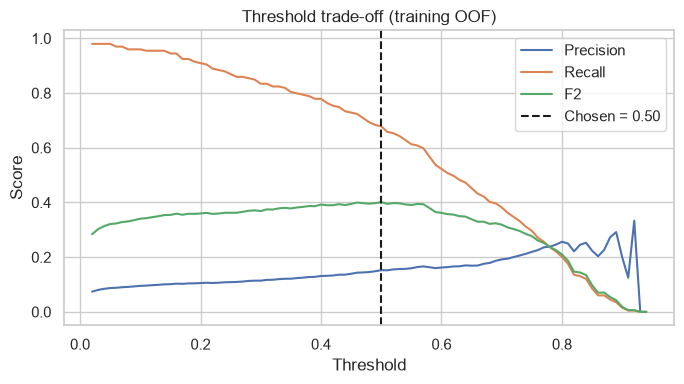

In [24]:
# Pick the best tuned model by cross-validated PR-AUC (training data only).
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best_model = tuned[best_name].best_estimator_
print("Selected model:", best_name)

oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.arange(0.02, 0.95, 0.01)
f2_scores = [fbeta_score(y_train, (oof_proba >= t).astype(int), beta=2) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(f2_scores))])
print(f"Chosen threshold (max F2 on out-of-fold training predictions): {best_threshold:.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
prec = [precision_score(y_train, (oof_proba >= t).astype(int), zero_division=0) for t in thresholds]
rec = [recall_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds]
ax.plot(thresholds, prec, label="Precision")
ax.plot(thresholds, rec, label="Recall")
ax.plot(thresholds, f2_scores, label="F2")
ax.axvline(best_threshold, color="k", linestyle="--", label=f"Chosen = {best_threshold:.2f}")
ax.set_xlabel("Threshold"); ax.set_ylabel("Score"); ax.legend(); ax.set_title("Threshold trade-off (training OOF)")
plt.tight_layout(); plt.show()

## 12. Final evaluation on the held-out test set

In [25]:
default_res = evaluate(best_name + " @ 0.50", best_model, X_test, y_test, threshold=0.5)
tuned_thr_res = evaluate(best_name + f" @ {best_threshold:.2f}", best_model, X_test, y_test,
                         threshold=best_threshold)
final = pd.DataFrame([default_res, tuned_thr_res]).set_index("Model").round(3)
final

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
XGBoost (tuned) @ 0.50,0.788,0.156,0.76,0.259,0.829,0.22
XGBoost (tuned) @ 0.50,0.788,0.156,0.76,0.259,0.829,0.22


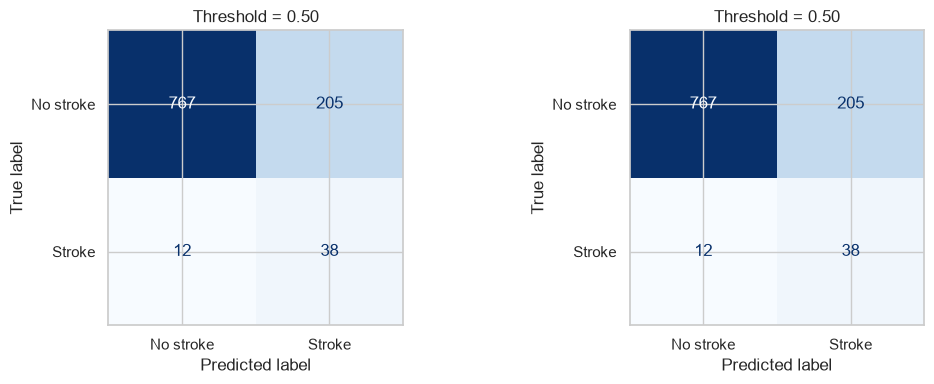

Classification report at threshold 0.50:

              precision    recall  f1-score   support

   No stroke       0.98      0.79      0.88       972
      Stroke       0.16      0.76      0.26        50

    accuracy                           0.79      1022
   macro avg       0.57      0.77      0.57      1022
weighted avg       0.94      0.79      0.85      1022



In [26]:
test_proba = best_model.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, thr in zip(axes, [0.5, best_threshold]):
    pred = (test_proba >= thr).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["No stroke", "Stroke"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Threshold = {thr:.2f}")
plt.tight_layout(); plt.show()

print(f"Classification report at threshold {best_threshold:.2f}:\n")
print(classification_report(y_test, (test_proba >= best_threshold).astype(int),
                            target_names=["No stroke", "Stroke"], zero_division=0))

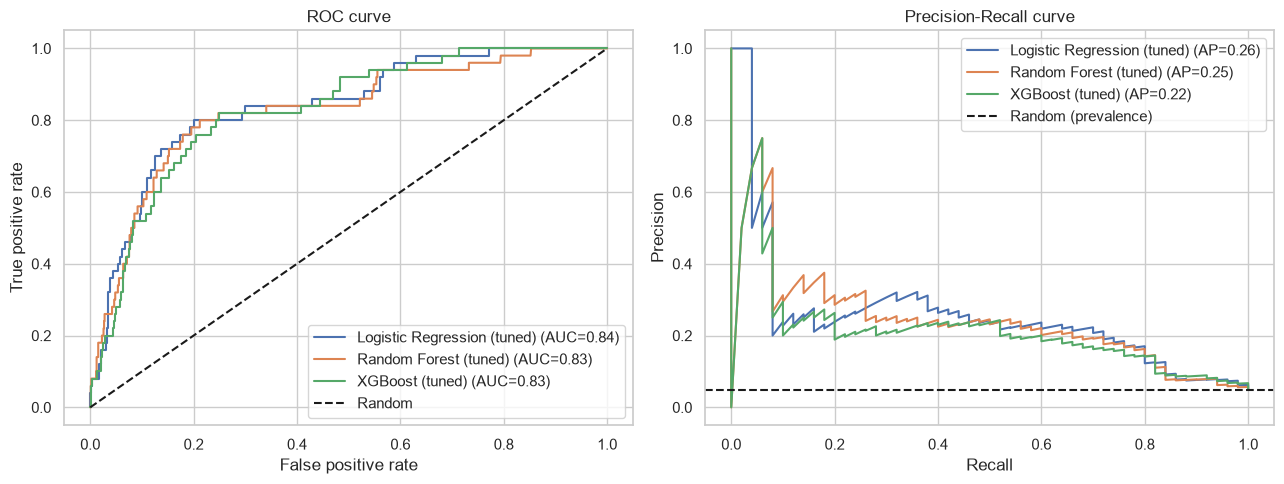

In [27]:
# ROC and Precision-Recall curves for all tuned models on the test set
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, s in tuned.items():
    p = s.best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.2f})")
    axes[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve"); axes[0].legend()
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Random (prevalence)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve"); axes[1].legend()
plt.tight_layout(); plt.show()

## 13. Model interpretation
**Permutation importance** shuffles one feature at a time on the test set and measures how much PR-AUC drops. It works on the original columns and is model-agnostic.

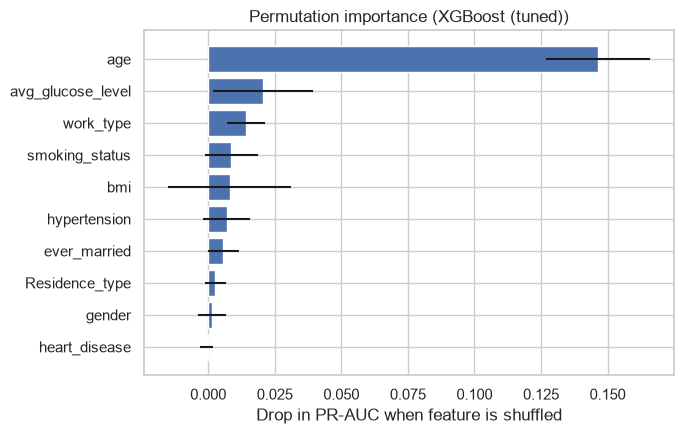

age                  0.1464
avg_glucose_level    0.0207
work_type            0.0141
smoking_status       0.0087
bmi                  0.0081
hypertension         0.0069
ever_married         0.0057
Residence_type       0.0026
gender               0.0015
heart_disease       -0.0005
dtype: float64

In [28]:
perm = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
err = pd.Series(perm.importances_std, index=X_test.columns)[imp.index]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, xerr=err.values)
ax.set_xlabel("Drop in PR-AUC when feature is shuffled")
ax.set_title(f"Permutation importance ({best_name})")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4)

**SHAP** shows how each feature pushes an individual prediction up or down. (If the `shap` library is not installed, this cell is skipped.)

Background dataset has 4087 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4087 when initializing the masker.


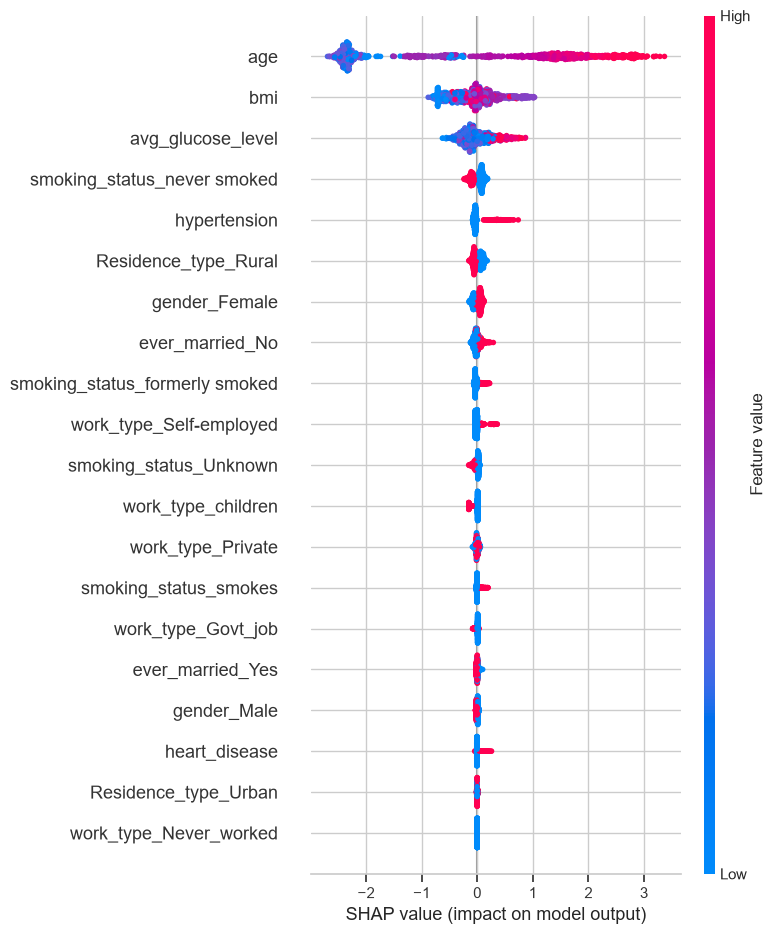

In [29]:
try:
    import shap
    prep = best_model.named_steps["prep"]
    clf = best_model.named_steps["clf"]
    Xt_train = prep.transform(X_train)
    Xt_test = prep.transform(X_test)
    feat_names = prep.get_feature_names_out()
    feat_names = [f.split("__", 1)[-1] for f in feat_names]

    explainer = shap.Explainer(clf, Xt_train)
    sv = explainer(Xt_test)
    values = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values

    shap.summary_plot(values, Xt_test, feature_names=feat_names, show=True)
except Exception as e:
    print("SHAP skipped:", repr(e))

## 14. Try it: predict risk for a new patient

In [30]:
def predict_risk(patient: dict, model=best_model, threshold=best_threshold):
    row = pd.DataFrame([patient])[X_train.columns]
    p = model.predict_proba(row)[0, 1]
    label = "HIGH risk (flag for follow-up)" if p >= threshold else "lower risk"
    return p, label

example = {"gender": "Male", "age": 72, "hypertension": 1, "heart_disease": 1,
           "ever_married": "Yes", "work_type": "Private", "Residence_type": "Urban",
           "avg_glucose_level": 190.0, "bmi": 31.5, "smoking_status": "formerly smoked"}
p, label = predict_risk(example)
print(f"Predicted stroke probability: {p:.1%}  ->  {label}")

Predicted stroke probability: 85.0%  ->  HIGH risk (flag for follow-up)


## 15. Conclusions

In [31]:
r = tuned_thr_res
print(f"Best model      : {best_name}")
print(f"Decision cutoff : {best_threshold:.2f} (chosen on training out-of-fold predictions)")
print(f"Test recall     : {r['Recall']:.2f}   (share of actual stroke cases caught)")
print(f"Test precision  : {r['Precision']:.2f}   (share of flagged patients who truly had a stroke)")
print(f"Test ROC-AUC    : {r['ROC-AUC']:.2f}")
print(f"Test PR-AUC     : {r['PR-AUC']:.2f}   (random guessing would be about {y_test.mean():.2f})")

Best model      : XGBoost (tuned)
Decision cutoff : 0.50 (chosen on training out-of-fold predictions)
Test recall     : 0.76   (share of actual stroke cases caught)
Test precision  : 0.16   (share of flagged patients who truly had a stroke)
Test ROC-AUC    : 0.83
Test PR-AUC     : 0.22   (random guessing would be about 0.05)


**Summary**
- A strongly imbalanced target means accuracy is not a useful metric; the baseline shows this clearly.
- Handling imbalance (class weights or SMOTE), tuning, and lowering the decision threshold trade precision for much higher recall, which suits a screening use case.
- Age, glucose level, hypertension and heart disease are the main drivers (confirm with the importance and SHAP plots above).
- All preprocessing, resampling and tuning were done inside pipelines or on training data only, so the test results are not inflated by leakage.

**Limitations**
- Only about 200 positive cases in total, so test metrics have wide uncertainty (the cross-validation standard deviations show this).
- Precision stays low even with a good model: most flagged patients will not be stroke cases. The model is a screening aid, not a diagnostic tool.
- The dataset is observational and the features are limited (no cholesterol, blood-pressure readings, family history, medication). The target is "has had a stroke", so some features (for example BMI, smoking status) may reflect life after the event rather than risk before it.
- No external validation on a different hospital or population.

**Future work**
- Collect richer clinical features and more positive cases.
- Calibrate predicted probabilities (Platt scaling or isotonic regression).
- Try cost-sensitive learning with explicit costs for false negatives and false positives.
- Validate on external data, and check fairness across gender and age groups.

In [32]:
import pandas as pd

df = pd.read_csv("healthcare-dataset-stroke-data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [33]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStroke Distribution:")
print(df["stroke"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB

Missing Values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_marr

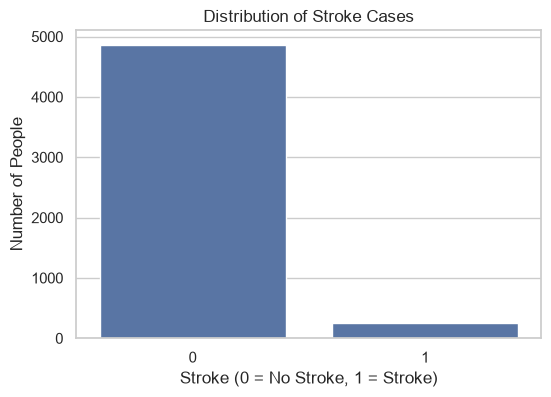

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="stroke")

plt.title("Distribution of Stroke Cases")
plt.xlabel("Stroke (0 = No Stroke, 1 = Stroke)")
plt.ylabel("Number of People")

plt.show()

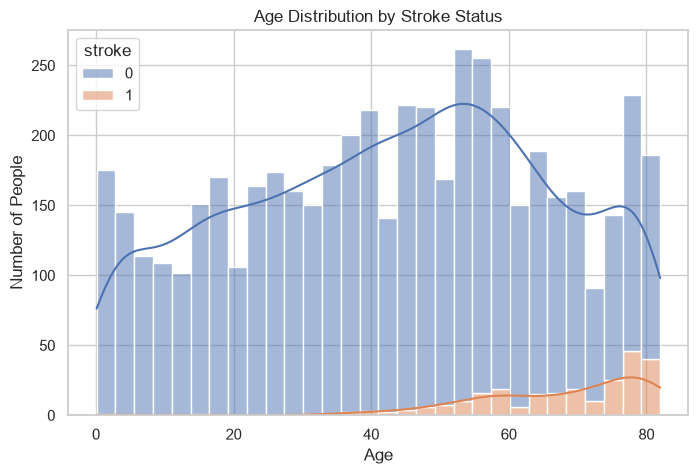

In [35]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue="stroke",
    bins=30,
    kde=True,
    multiple="stack"
)

plt.title("Age Distribution by Stroke Status")
plt.xlabel("Age")
plt.ylabel("Number of People")

plt.show()

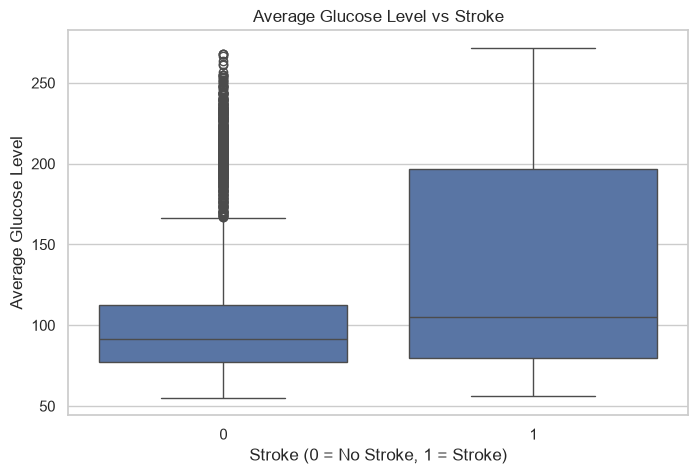

In [36]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="stroke", y="avg_glucose_level")

plt.title("Average Glucose Level vs Stroke")
plt.xlabel("Stroke (0 = No Stroke, 1 = Stroke)")
plt.ylabel("Average Glucose Level")

plt.show()

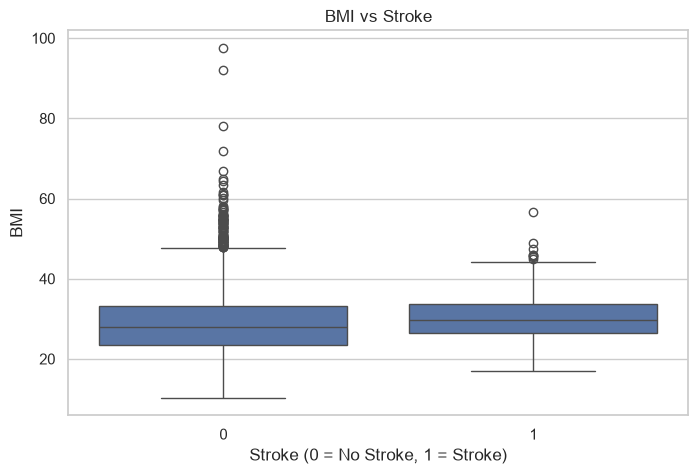

In [37]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="stroke", y="bmi")

plt.title("BMI vs Stroke")
plt.xlabel("Stroke (0 = No Stroke, 1 = Stroke)")
plt.ylabel("BMI")

plt.show()

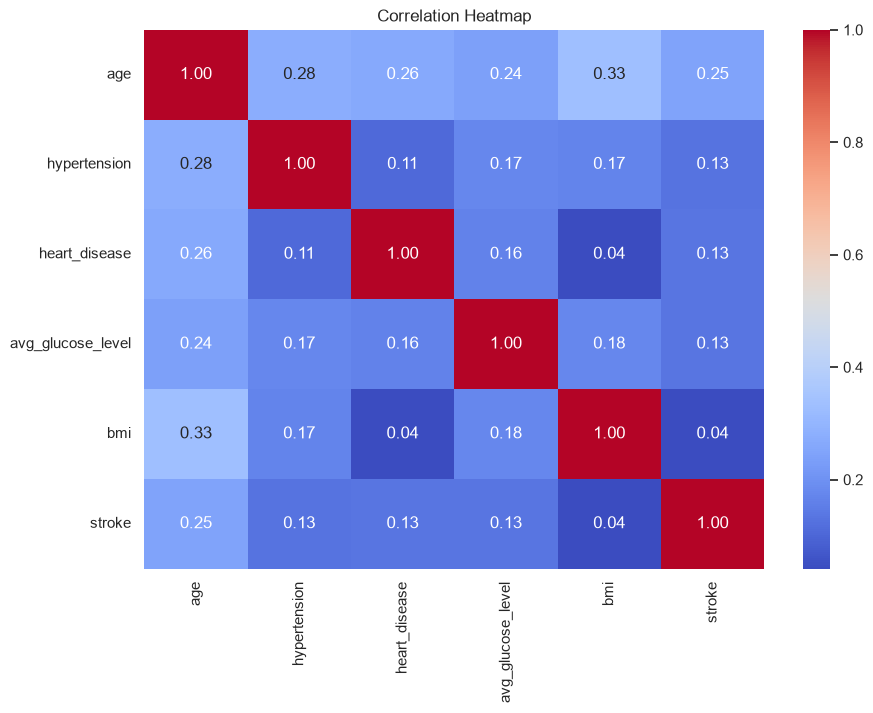

In [38]:
plt.figure(figsize=(10, 7))

numeric_df = df.select_dtypes(include="number").drop(columns=["id"])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [39]:
# Create a copy of the original dataset
data = df.copy()

# Remove ID column
data.drop("id", axis=1, inplace=True)

# Fill missing BMI values with median
data["bmi"] = data["bmi"].fillna(data["bmi"].median())

# Remove the row with gender = Other
data = data[data["gender"] != "Other"]

# Check the cleaned dataset
print("Shape after cleaning:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nGender categories:")
print(data["gender"].value_counts())

Shape after cleaning: (5109, 11)

Missing values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Gender categories:
gender
Female    2994
Male      2115
Name: count, dtype: int64


In [40]:
X = data.drop("stroke", axis=1)
y = data["stroke"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (5109, 10)
Target shape: (5109,)

Target distribution:
stroke
0    4860
1     249
Name: count, dtype: int64


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training data shape: (4087, 10)
Testing data shape: (1022, 10)

Training target distribution:
stroke
0    3888
1     199
Name: count, dtype: int64

Testing target distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [42]:
# Recreate the cleaned dataset without filling missing BMI yet
data = df.copy()

data.drop("id", axis=1, inplace=True)
data = data[data["gender"] != "Other"]

# Separate features and target
X = data.drop("stroke", axis=1)
y = data["stroke"]

# Split the data again
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Identify numerical and categorical columns
numeric_features = [
    "age",
    "hypertension",
    "heart_disease",
    "avg_glucose_level",
    "bmi"
]

categorical_features = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)

Numerical features: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Categorical features: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

Training data: (4087, 10)
Testing data: (1022, 10)


In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [44]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Create a complete pipeline with preprocessing and SMOTE
smote_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42))
])

# Apply preprocessing and SMOTE to training data
X_train_resampled, y_train_resampled = smote_pipeline.fit_resample(
    X_train, y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

Before SMOTE:
stroke
0    3888
1     199
Name: count, dtype: int64

After SMOTE:
stroke
0    3888
1    3888
Name: count, dtype: int64


In [45]:
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline

# Create Logistic Regression pipeline
lr_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Make predictions on test data
y_pred_lr = lr_model.predict(X_test)

# Get prediction probabilities
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

# Display evaluation metrics
print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_lr, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))
print("PR-AUC:", average_precision_score(y_test, y_prob_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.7397260273972602
Precision: 0.13513513513513514
Recall: 0.8
F1 Score: 0.23121387283236994
ROC-AUC: 0.841440329218107
PR-AUC: 0.2805517313758231

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.74      0.84       972
           1       0.14      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022



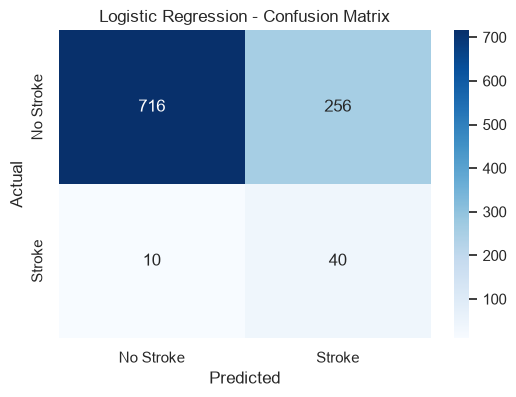

In [47]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [48]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest pipeline
rf_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [49]:
# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Get prediction probabilities
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Display evaluation metrics
print("RANDOM FOREST RESULTS")
print("---------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_rf, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("PR-AUC:", average_precision_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

RANDOM FOREST RESULTS
---------------------
Accuracy: 0.9315068493150684
Precision: 0.14285714285714285
Recall: 0.08
F1 Score: 0.10256410256410256
ROC-AUC: 0.7490020576131688
PR-AUC: 0.13331912694951917

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       972
           1       0.14      0.08      0.10        50

    accuracy                           0.93      1022
   macro avg       0.55      0.53      0.53      1022
weighted avg       0.91      0.93      0.92      1022



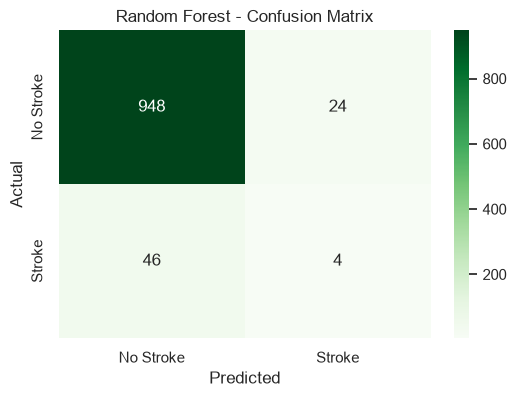

In [50]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [51]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ],
    "PR-AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf)
    ]
})

results.set_index("Model", inplace=True)

results.round(3)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.740,0.135,0.80,0.231,0.841,0.281
Random Forest,0.932,0.143,0.08,0.103,0.749,0.133


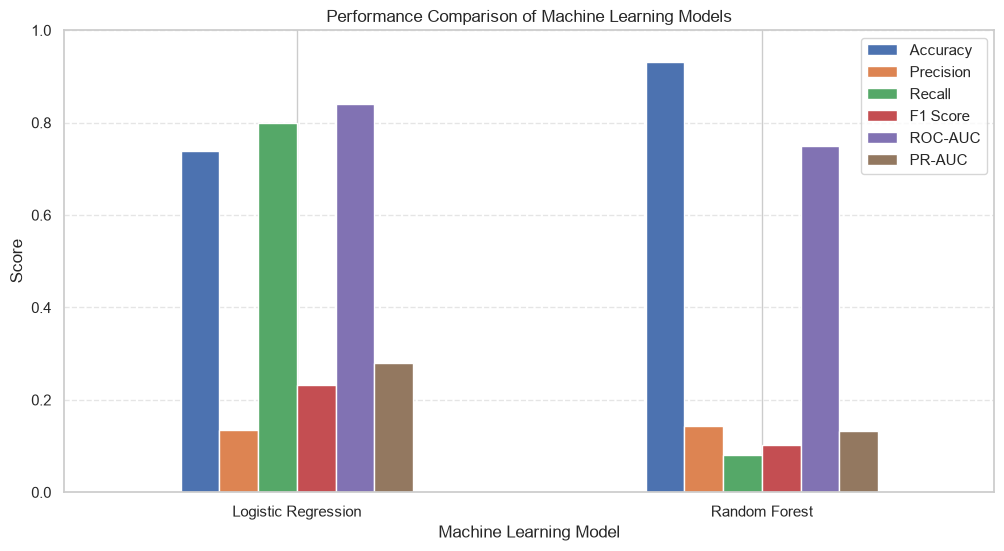

In [52]:
results[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [53]:
print("Stroke Prediction Project")
print("Dataset shape:", df.shape)
print("Logistic Regression Recall:", recall_score(y_test, y_pred_lr))
print("Random Forest Recall:", recall_score(y_test, y_pred_rf))

Stroke Prediction Project
Dataset shape: (5110, 12)
Logistic Regression Recall: 0.8
Random Forest Recall: 0.08
